# Perfilamiento del dataset Spotify

## Objetivo

Este notebook tiene como objetivo realizar el perfilamiento exploratorio
del dataset de Spotify antes de cualquier transformación, limpieza o
validación de calidad.

El análisis busca obtener evidencia sobre:

- Estructura del dataset
- Completitud
- Unicidad y duplicación
- Contenido categórico
- Contenido numérico
- Contenido temporal
- Posibles riesgos de calidad de datos

Los resultados obtenidos servirán posteriormente como evidencia para
definir reglas de calidad y expectativas de Great Expectations.

## Fuente de datos

**Fuente:** Spotify CSV

**Tipo de fuente:** Archivo CSV

**Naturaleza:** Dataset transaccional/detalle de pistas musicales

**Uso dentro del proyecto:** Fuente para el proceso de integración
con la información de Grammy Awards.

In [35]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

In [36]:
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "spotify_dataset.csv"

DATA_PATH

WindowsPath('c:/Users/Monica/Desktop/ETL/Workshop2/data/spotify_dataset.csv')

In [37]:
df = pd.read_csv(DATA_PATH, sep=',', encoding='latin1')

In [38]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [39]:
df.shape

(114000, 21)

In [40]:
print(f"Número de filas: {df.shape[0]:,}")
print(f"Número de columnas: {df.shape[1]}")

Número de filas: 114,000
Número de columnas: 21


In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [42]:
structure = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "nulls": df.isna().sum(),
})

structure

,column,dtype,non_null,nulls
Unnamed: 0,Unnamed: 0,int64,114000,0
track_id,track_id,str,114000,0
artists,artists,str,113999,1
album_name,album_name,str,113999,1
track_name,track_name,str,113999,1
popularity,popularity,int64,114000,0
duration_ms,duration_ms,int64,114000,0
explicit,explicit,bool,114000,0
danceability,danceability,float64,114000,0
energy,energy,float64,114000,0


## Observaciones iniciales

A partir de la inspección inicial se observa:

- El dataset contiene 114.000 registros y 21 atributos.
- Los tipos técnicos identificados por pandas son int64, str y object (según la representación mostrada en el DataFrame).
- Se identifican track_id, artists, album_name, track_name, explicit y track_genre campos de tipo texto.
- Se identifican 15 campos numéricos.
- Se identifican 0 campos booleanos.
- No se identifican campos temporales.

Estas observaciones serán profundizadas en las secciones
correspondientes de estructura, completitud, unicidad, contenido
categórico, contenido numérico y contenido temporal.

## 2. Structure

Esta sección analiza la estructura de la fuente antes de realizar cualquier transformación. Se revisan las columnas, tipos técnicos, tipos semánticos preliminares, unidades o escalas y posibles atributos relevantes para el proceso posterior.

In [43]:
structure = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "nulls": df.isna().sum(),
    "unique_values": df.nunique(dropna=False)
})

structure

,column,dtype,non_null,nulls,unique_values
Unnamed: 0,Unnamed: 0,int64,114000,0,114000
track_id,track_id,str,114000,0,89741
artists,artists,str,113999,1,31438
album_name,album_name,str,113999,1,46590
track_name,track_name,str,113999,1,73609
popularity,popularity,int64,114000,0,101
duration_ms,duration_ms,int64,114000,0,50697
explicit,explicit,bool,114000,0,2
danceability,danceability,float64,114000,0,1174
energy,energy,float64,114000,0,2083


In [44]:
structure["dtype"].value_counts()

dtype
float64    9
int64      6
str        5
bool       1
Name: count, dtype: int64

### Significado y naturaleza de los atributos

Se realizará una caracterización preliminar de cada atributo considerando su significado, naturaleza, unidad de medida, escala y dominio esperado. Esta caracterización permitirá distinguir entre medidas numéricas, variables categóricas codificadas e identificadores.

In [45]:
semantic_dictionary = pd.DataFrame([
    ["Column1", "Índice técnico", "Identificador técnico", "Secuencial"],
    ["track_id", "Identificador de pista", "Identificador", "Texto"],
    ["artists", "Artista(s)", "Texto / multivaluado", "Texto"],
    ["album_name", "Nombre del álbum", "Texto", "Texto"],
    ["track_name", "Nombre de la pista", "Texto", "Texto"],
    ["popularity", "Popularidad", "Numérica", "Escala 0-100"],
    ["duration_ms", "Duración", "Numérica", "Milisegundos"],
    ["explicit", "Contenido explícito", "Categórica binaria", "2 categorías"],
    ["danceability", "Bailabilidad", "Numérica", "Escala"],
    ["energy", "Energía", "Numérica", "Escala"],
    ["key", "Tonalidad", "Categórica codificada", "12 valores"],
    ["loudness", "Volumen", "Numérica", "Escala"],
    ["mode", "Modalidad", "Categórica binaria", "2 valores"],
    ["speechiness", "Presencia de voz hablada", "Numérica", "Escala"],
    ["acousticness", "Acousticidad", "Numérica", "Escala"],
    ["instrumentalness", "Instrumentalidad", "Numérica", "Escala"],
    ["liveness", "Probabilidad de interpretación en vivo", "Numérica", "Escala"],
    ["valence", "Valencia musical", "Numérica", "Escala"],
    ["tempo", "Tempo", "Numérica", "BPM"],
    ["time_signature", "Compás", "Categórica codificada", "Valores discretos"],
    ["track_genre", "Género musical", "Categórica", "114 categorías"],
], columns=["column", "meaning", "semantic_type", "scale_or_unit"])

semantic_dictionary

,column,meaning,semantic_type,scale_or_unit
0,Column1,Índice técnico,Identificador técnico,Secuencial
1,track_id,Identificador de pista,Identificador,Texto
2,artists,Artista(s),Texto / multivaluado,Texto
3,album_name,Nombre del álbum,Texto,Texto
4,track_name,Nombre de la pista,Texto,Texto
5,popularity,Popularidad,Numérica,Escala 0-100
6,duration_ms,Duración,Numérica,Milisegundos
7,explicit,Contenido explícito,Categórica binaria,2 categorías
8,danceability,Bailabilidad,Numérica,Escala
9,energy,Energía,Numérica,Escala


In [46]:
semantic_type = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(dropna=False)
})

semantic_type["semantic_type"] = (
    semantic_type["column"]
    .map(
        semantic_dictionary.set_index("column")["semantic_type"]
    )
)

semantic_type

,column,dtype,unique_values,semantic_type
Unnamed: 0,Unnamed: 0,int64,114000,NaN
track_id,track_id,str,89741,Identificador
artists,artists,str,31438,Texto / multivaluado
album_name,album_name,str,46590,Texto
track_name,track_name,str,73609,Texto
popularity,popularity,int64,101,Numérica
duration_ms,duration_ms,int64,50697,Numérica
explicit,explicit,bool,2,Categórica binaria
danceability,danceability,float64,1174,Numérica
energy,energy,float64,2083,Numérica


## 3 Completitud

### Porcentajes

In [47]:
nulls_percentage = pd.DataFrame({
    "column": df.columns,
    "null_count": df.isna().sum().values,
    "null_percentage": (df.isna().mean() * 100).values
})

nulls_percentage["null_percentage"] = (
    nulls_percentage["null_percentage"].round(4)
)

nulls_percentage

,column,null_count,null_percentage
0,Unnamed: 0,0,0.0000
1,track_id,0,0.0000
2,artists,1,0.0009
3,album_name,1,0.0009
4,track_name,1,0.0009
5,popularity,0,0.0000
6,duration_ms,0,0.0000
7,explicit,0,0.0000
8,danceability,0,0.0000
9,energy,0,0.0000


### Patrones de ausencia

Aquí ya no analizamos qué columnas tienen nulos, sino si los nulos se concentran en determinados registros.

In [48]:
missing_pattern = (
    df.isna()
    .groupby(list(df.columns))
    .size()
    .reset_index(name="row_count")
)

missing_pattern

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,row_count
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,113999
1,False,False,True,True,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,1


## Hallazgos

In [49]:
completeness_findings = pd.DataFrame([
    [
        "album_name",
        "Presenta un valor faltante",
        "1 de 114000 registros (0.0009 %)",
        "Bajo",
        "Evaluar tratamiento del valor faltante"
    ],
    [
        "track_name",
        "Presenta un valor faltante",
        "1 de 114000 registros (0.0009 %)",
        "Bajo",
        "Evaluar tratamiento del valor faltante"
    ],
    [
        "Dataset",
        "Alta completitud general",
        "113999 de 114000 registros no presentan valores nulos",
        "Muy bajo",
        "No se requiere una estrategia general de imputación"
    ]
], columns=[
    "scope",
    "finding",
    "evidence",
    "risk",
    "etl_implication"
])

completeness_findings

,scope,finding,evidence,risk,etl_implication
0,album_name,Presenta un valor faltante,1 de 114000 registros (0.0009 %),Bajo,Evaluar tratamiento del valor faltante
1,track_name,Presenta un valor faltante,1 de 114000 registros (0.0009 %),Bajo,Evaluar tratamiento del valor faltante
2,Dataset,Alta completitud general,113999 de 114000 registros no presentan valore...,Muy bajo,No se requiere una estrategia general de imput...


### Unicidad y duplicaciones

## Duplicados completos

Buscamos los duplicados exactos


In [50]:
complete_duplicates = df.duplicated(keep=False)

duplicate_rows = df[complete_duplicates]

print(f"Registros involucrados en duplicados completos: {len(duplicate_rows)}")
print(f"Cantidad de grupos de duplicados: {df.duplicated().sum()}")

duplicate_rows

Registros involucrados en duplicados completos: 0
Cantidad de grupos de duplicados: 0


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre


### track_id

Analizar la unicidad del posible identificador principal

In [51]:
track_id_unique = df["track_id"].nunique()
track_id_duplicates = df["track_id"].duplicated().sum()

print(f"Registros totales: {len(df)}")
print(f"track_id únicos: {track_id_unique}")
print(f"Registros con track_id duplicado: {track_id_duplicates}")

Registros totales: 114000
track_id únicos: 89741
Registros con track_id duplicado: 24259


Examinar cuales son estos registros repeditos

In [52]:
duplicated_track_ids = (
    df[df["track_id"].duplicated(keep=False)]
    .sort_values("track_id")
)

duplicated_track_ids

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
15028,15028,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.316000,0.000001,0.1170,0.406,143.064,4,chill
103211,103211,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.316000,0.000001,0.1170,0.406,143.064,4,soul
85578,85578,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.019400,0.088100,0.3290,0.700,183.571,1,punk-rock
100420,100420,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.019400,0.088100,0.3290,0.700,183.571,1,ska
91801,91801,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.001210,0.000000,0.0995,0.236,148.033,4,rock
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72679,72679,7zv2vmZq8OjS54BxFzI2wM,Attila,Soundtrack to a Party (Bonus),Lets Start the Party,25,125859,True,0.592,0.932,...,-5.412,1,0.0558,0.000005,0.859000,0.0730,0.677,133.987,4,metalcore
22326,22326,7zv2vmZq8OjS54BxFzI2wM,Attila,Soundtrack to a Party (Bonus),Lets Start the Party,25,125859,True,0.592,0.932,...,-5.412,1,0.0558,0.000005,0.859000,0.0730,0.677,133.987,4,death-metal
2004,2004,7zwn1eykZtZ5LODrf7c0tS,The Neighbourhood,Hard To Imagine The Neighbourhood Ever Changing,You Get Me So High,83,153000,False,0.551,0.881,...,-6.099,0,0.0542,0.186000,0.079100,0.1520,0.387,88.036,4,alt-rock
3100,3100,7zwn1eykZtZ5LODrf7c0tS,The Neighbourhood,Hard To Imagine The Neighbourhood Ever Changing,You Get Me So High,83,153000,False,0.551,0.881,...,-6.099,0,0.0542,0.186000,0.079100,0.1520,0.387,88.036,4,alternative


Identificar la cantidad de veces que se repiten cada fila

In [53]:
track_id_frequency = (
    df["track_id"]
    .value_counts()
    .loc[lambda x: x > 1]
    .reset_index()
)

track_id_frequency.columns = ["track_id", "row_count"]

track_id_frequency

,track_id,row_count
0,6S3JlDAGk3uu3NtZbPnuhS,9
1,2kkvB3RNRzwjFdGhaUA0tz,8
2,2Ey6v4Sekh3Z0RUSISRosD,8
3,2vU6bm5hVF2idVknGzqyPL,7
4,4GPQDyw9hC1DiZVh0ouDVL,7
...,...,...
16636,0sSjIvTvd6fUSZZ5rnTPDW,2
16637,2zg3iJW4fK7KZgHOvJU67z,2
16638,46FPub2Fewe7XrgM0smTYI,2
16639,6qVA1MqDrDKfk9144bhoKp,2


Examinar posibles candidatos como identificadores

In [54]:
identification_candidates = pd.DataFrame({
    "column": df.columns,
    "unique_values": [
        df[col].nunique(dropna=False)
        for col in df.columns
    ]
})

identification_candidates["uniqueness_percentage"] = (
    identification_candidates["unique_values"]
    / len(df)
    * 100
).round(4)

identification_candidates.sort_values(
    "uniqueness_percentage",
    ascending=False
)

,column,unique_values,uniqueness_percentage
0,Unnamed: 0,114000,100.0000
1,track_id,89741,78.7202
4,track_name,73609,64.5693
6,duration_ms,50697,44.4711
3,album_name,46590,40.8684
18,tempo,45653,40.0465
2,artists,31438,27.5772
11,loudness,19480,17.0877
15,instrumentalness,5346,4.6895
14,acousticness,5061,4.4395


Duplicados semanticos

In [55]:
semantic_key = [
    "artists",
    "album_name",
    "track_name"
]

semantic_duplicates = (
    df[
        df.duplicated(
            subset=semantic_key,
            keep=False
        )
    ]
    .sort_values(semantic_key)
)

semantic_duplicates

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
58516,58516,5h7RBt7uQCF788tr9Zy92j,(Hed) P.E.,Broke,Crazy Legs,25,242800,False,0.607,0.775,...,-5.427,1,0.2670,0.001950,0.000001,0.0915,0.736,102.051,4,industrial
58857,58857,5igKQzi92vVl9Pjj86d42O,(Hed) P.E.,Broke,Crazy Legs,22,242960,True,0.523,0.810,...,-5.265,1,0.2940,0.001840,0.000001,0.0744,0.738,102.863,4,industrial
58306,58306,7kv31DonKok7StOsCdvoBT,(Hed) P.E.,Broke,Waiting to Die,27,194800,True,0.581,0.962,...,-5.964,1,0.1210,0.000262,0.000011,0.1320,0.484,115.226,4,industrial
58874,58874,0aiP8ezzmk3W1GRvnQYDCA,(Hed) P.E.,Broke,Waiting to Die,22,194626,False,0.577,0.964,...,-6.116,1,0.1200,0.000276,0.000048,0.1550,0.533,115.250,4,industrial
63488,63488,3KYALFgiqZLKScioJGqz8a,10-FEET,VANDALIZE,SHOES,34,137893,False,0.517,0.981,...,-1.222,1,0.1100,0.069000,0.000000,0.0610,0.654,124.821,4,j-rock
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72502,72502,171lZBEaiKMrV9V8c6QvPE,è±å·ãã,NEET GAME,NEET GAME,52,169500,False,0.492,0.974,...,-3.913,1,0.1050,0.000025,0.000028,0.0646,0.192,100.946,4,metalcore
99361,99361,6la3Kme7O7D01fJPxgpAS5,è©¹é¯å©·,è¨£æ,è¨£æ (åéãè¼è­è¨£ãçé ­æ²),69,189295,False,0.450,0.620,...,-6.492,1,0.0365,0.313000,0.000000,0.0672,0.169,142.026,4,singer-songwriter
102361,102361,6la3Kme7O7D01fJPxgpAS5,è©¹é¯å©·,è¨£æ,è¨£æ (åéãè¼è­è¨£ãçé ­æ²),69,189295,False,0.450,0.620,...,-6.492,1,0.0365,0.313000,0.000000,0.0672,0.169,142.026,4,songwriter
12466,12466,1o7LoJTQd4Js16rHjTKAc9,é³ç§é,ç¬¬äºéå½©è¹,å ­æå¤©,23,178493,False,0.487,0.414,...,-10.743,1,0.0282,0.438000,0.000004,0.3490,0.745,141.018,4,cantopop


In [56]:
semantic_duplicate_count = df.duplicated(
    subset=semantic_key,
    keep=False
).sum()

print(
    f"Registros involucrados en posibles duplicaciones semánticas: "
    f"{semantic_duplicate_count}"
)

Registros involucrados en posibles duplicaciones semánticas: 41415


In [57]:
semantic_frequency = (
    df.groupby(semantic_key, dropna=False)
      .size()
      .reset_index(name="row_count")
      .query("row_count > 1")
      .sort_values("row_count", ascending=False)
)

semantic_frequency

,artists,album_name,track_name,row_count
37978,Jimmy Eat World,Alternative Christmas 2022,Last Christmas,12
78698,The Smashing Pumpkins,Alternative Christmas 2022,Christmastime,10
37970,Jimmy Buffett,Best 70s Rock Tunes,Survive,9
7996,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,9
21633,Don McLean,Best 70s Rock Tunes,If We Try,9
...,...,...,...,...
88846,ÐÐ°Ð»Ð¸Ð½Ð° ÐÐ°ÑÐµÐ²Ð°,ÐÐµ Ð¿ÑÐ¾Ð±ÑÐ¶Ð´Ð°Ð¹ Ð²Ð¾ÑÐ¿Ð¾Ð¼Ð¸Ð½Ð°Ð½Ð¸...,"Ð£Ð¹Ð´Ð¸, ÑÐ¾Ð²ÑÐµÐ¼ ÑÐ¹Ð´Ð¸",2
88840,ÐÐ»Ð°Ð´Ð¸Ð¼Ð¸Ñ ÐÑÐ½ÑÐ¸ÐºÐ¾Ð²,Ð¡ÐµÐ²Ð°ÑÑÐ¾Ð¿Ð¾Ð»ÑÑÐºÐ¸Ð¹ ÐÐ°Ð»ÑÑ (194...,"Ð¨ÑÐ¼Ð¸Ñ Ð²Ð¾Ð»Ð½Ð°, Ð·Ð²ÐµÐ½Ð¸Ñ ÑÑÑÑÐ½Ð°",2
88835,ÐÐ»Ð°Ð´Ð¸Ð¼Ð¸Ñ ÐÑÐ½ÑÐ¸ÐºÐ¾Ð²,ÐÑ Ð² Ð¶Ð¸Ð·Ð½Ñ Ð¸Ð´ÐµÐ¼ (1936 - 1958),ÐÐ° ÐºÑÐµÐ¹ÑÐµÑÐµ ÐÐ¾Ð»Ð¾ÑÐ¾Ð²,2
88821,ÐÐ°Ð»ÐµÑÐ¸Ð¹ ÐÐ³Ð°ÑÐ¾Ð½Ð¾Ð²,ÐÐ° ÐºÐ¾ÑÐ´Ð¾Ð½Ð¾Ð¼ â Ð»ÑÐ±Ð¾Ð²Ñ,Ð¨Ð°ÑÐ¼Ð°Ð½ÑÐ¸Ðº,2


In [58]:
track_genre_combinations = (
    df.groupby("track_id")["track_genre"]
      .nunique()
)

print(
    "track_id con más de un género:",
    (track_genre_combinations > 1).sum()
)

print(
    "track_id con un solo género:",
    (track_genre_combinations == 1).sum()
)

track_id con más de un género: 16299
track_id con un solo género: 73442


In [59]:
track_id_genre_frequency = (
    df.groupby(["track_id", "track_genre"])
      .size()
      .reset_index(name="row_count")
)

track_id_genre_frequency[
    track_id_genre_frequency["row_count"] > 1
].sort_values(
    "row_count",
    ascending=False
)

,track_id,track_genre,row_count
37661,2abeQBWSIzjO8J1KrPFZHy,romance,3
10677,0jI5ex80hYYbLQsX3G5Ze7,german,3
73244,52VSOpFbg4GBpPNNv4ulbP,romance,3
85585,5sP7Jb0FBF2fatb1CZ3zpa,german,3
91902,6IzTjoU9t5DiBN4BmiWBB8,german,3
...,...,...,...
6357,0RPOy0HWyY3bLm40pm3T8s,classical,2
7184,0UswNGtK684rqSxXFP18Uw,romance,2
7778,0XDo1WmF8c70NuTZcMP2FH,dance,2
7950,0Xyy5ASa9iuqIgzH2mY9T6,iranian,2


In [60]:
track_genre_repeated = (
    df.groupby(["track_id", "track_genre"])
      .size()
      .reset_index(name="row_count")
)

track_genre_repeated = track_genre_repeated[
    track_genre_repeated["row_count"] > 1
]

print(
    "Combinaciones track_id + track_genre repetidas:",
    len(track_genre_repeated)
)

track_genre_repeated.head(20)

Combinaciones track_id + track_genre repetidas: 444


,track_id,track_genre,row_count
77,00JZ83w0Qm09f4PwWj06sM,honky-tonk,2
535,02KmEChUwcjxG3G29kbLFT,german,2
541,02MRylJ1WAgxzdqfNfdIsR,romance,2
744,03B8ZXUmuDpf59j5PIMFHq,classical,2
963,040CvqW0wo3b77EBRfgC14,classical,2
1068,04Rwlix3S6i0JeprqsC8Cx,dance,2
1082,04TwPJDhekbMYYKU5eiOsH,german,2
1136,04iTE6hn0yvbWHJXkIfLyy,classical,2
1235,05CrXeNWBptDD2zLAOaf2A,honky-tonk,2
1303,05WLq8RH59gRD3gMnmxUKb,romance,2


In [61]:
repeated_keys = track_genre_repeated[["track_id", "track_genre"]]

repeated_rows = df.merge(
    repeated_keys,
    on=["track_id", "track_genre"],
    how="inner"
)

comparison_columns = [
    col for col in df.columns
    if col not in ["Column1", "track_id", "track_genre"]
]

different_values = (
    repeated_rows
    .groupby(["track_id", "track_genre"])[comparison_columns]
    .nunique(dropna=False)
)

different_values["has_difference"] = (
    different_values > 1
).any(axis=1)

print(
    "Combinaciones repetidas con diferencias en otros atributos:",
    different_values["has_difference"].sum()
)

print(
    "Combinaciones repetidas completamente iguales:",
    (~different_values["has_difference"]).sum()
)

Combinaciones repetidas con diferencias en otros atributos: 444
Combinaciones repetidas completamente iguales: 0


## Hechos

1. No existen duplicados completos.
2. track_id presenta múltiples registros.
3. 24.259 registros corresponden a repeticiones de track_id.
4. 41.415 registros participan en coincidencias de artista + álbum + pista.
5. Los ejemplos muestran que una misma pista puede aparecer asociada a diferentes track_genre.
6. Se requiere determinar la granularidad efectiva del dataset antes de eliminar duplicaciones.
7. Se identificaron 444 combinaciones track_id + track_genre repetidas.
8. 894 registros pertenecen a grupos duplicados, pero 450 son duplicados respecto a una primera aparición.

Una fila parece representar una asociación entre una pista y un género, pero existen 444 asociaciones track_id + track_genre duplicadas físicamente

La granularidad candidata del dataset es una observación de una pista musical (track_id) asociada a un género (track_genre).

La evidencia disponible indica que track_id + track_genre es el mejor candidato para representar el grano de la fuente, dado que explica la multiplicidad de track_id y conserva prácticamente todos los atributos de la pista constantes.

Una observación de una pista dentro de un género.

### Análisis de la combinación track_id + track_genre

Se analizarán las combinaciones de identificador de pista y género para determinar si representan una posible unidad de granularidad y caracterizar las repeticiones observadas.

In [62]:
track_genre_counts = (
    df.groupby(["track_id", "track_genre"])
      .size()
      .reset_index(name="records")
)

track_genre_counts["records"].value_counts().sort_index()

records
1    113106
2       438
3         6
Name: count, dtype: int64

In [63]:
duplicated_track_genre = track_genre_counts[
    track_genre_counts["records"] > 1
].sort_values("records", ascending=False)

duplicated_track_genre.head(20)

,track_id,track_genre,records
37661,2abeQBWSIzjO8J1KrPFZHy,romance,3
10677,0jI5ex80hYYbLQsX3G5Ze7,german,3
73244,52VSOpFbg4GBpPNNv4ulbP,romance,3
85585,5sP7Jb0FBF2fatb1CZ3zpa,german,3
91902,6IzTjoU9t5DiBN4BmiWBB8,german,3
93322,6P2z6tZi1K8pyHXV1i0DnK,romance,3
1082,04TwPJDhekbMYYKU5eiOsH,german,2
1136,04iTE6hn0yvbWHJXkIfLyy,classical,2
1235,05CrXeNWBptDD2zLAOaf2A,honky-tonk,2
1303,05WLq8RH59gRD3gMnmxUKb,romance,2


### Caracterización de duplicaciones por track_id + track_genre

Se inspeccionarán los registros que comparten la misma combinación `track_id + track_genre` para determinar si las repeticiones son completamente equivalentes o presentan diferencias en otros atributos.

In [64]:
duplicated_keys = duplicated_track_genre[
    duplicated_track_genre["records"] > 1
][["track_id", "track_genre"]]

duplicated_records = df.merge(
    duplicated_keys,
    on=["track_id", "track_genre"],
    how="inner"
).sort_values(["track_id", "track_genre"])

duplicated_records.head(20)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
449,52714,00JZ83w0Qm09f4PwWj06sM,George Jones,With Love,A Good Year For The Roses,12,190546,False,0.491,0.3340,...,-9.684,1,0.0287,0.659,0.000016,0.1160,0.2490,91.674,4,honky-tonk
456,52766,00JZ83w0Qm09f4PwWj06sM,George Jones,With Love,A Good Year For The Roses,12,190546,False,0.491,0.3340,...,-9.684,1,0.0287,0.659,0.000016,0.1160,0.2490,91.674,4,honky-tonk
323,39275,02KmEChUwcjxG3G29kbLFT,Hans Zimmer;Henning Lohner;Martin Tillman;Fiac...,Hans Zimmer: Epic Scores,Shelter Mountain,16,250520,False,0.144,0.2620,...,-21.228,1,0.0641,0.876,0.755000,0.1440,0.0345,94.430,4,german
337,39307,02KmEChUwcjxG3G29kbLFT,Hans Zimmer;Henning Lohner;Martin Tillman;Fiac...,Hans Zimmer: Epic Scores,Shelter Mountain,16,250520,False,0.144,0.2620,...,-21.228,1,0.0641,0.876,0.755000,0.1440,0.0345,94.430,4,german
723,93331,02MRylJ1WAgxzdqfNfdIsR,Oleg Pogudin,ÐÑÐ±Ð¾Ð²Ñ Ð¸ ÑÐ°Ð·Ð»ÑÐºÐ°. ÐÐµÑÐ½Ð¸ ÐÑ...,"ÐÐ¾ÑÐ¾Ð´ Ð¿ÑÑÐ½ÑÐ¹, Ð³Ð¾ÑÐ¾Ð´ Ð±ÐµÐ´Ð½ÑÐ¹",0,114600,False,0.446,0.1210,...,-12.737,0,0.0414,0.937,0.000000,0.1250,0.1800,107.573,3,romance
767,93376,02MRylJ1WAgxzdqfNfdIsR,Oleg Pogudin,ÐÑÐ±Ð¾Ð²Ñ Ð¸ ÑÐ°Ð·Ð»ÑÐºÐ°. ÐÐµÑÐ½Ð¸ ÐÑ...,"ÐÐ¾ÑÐ¾Ð´ Ð¿ÑÑÐ½ÑÐ¹, Ð³Ð¾ÑÐ¾Ð´ Ð±ÐµÐ´Ð½ÑÐ¹",0,114600,False,0.446,0.1210,...,-12.737,0,0.0414,0.937,0.000000,0.1250,0.1800,107.573,3,romance
122,16747,03B8ZXUmuDpf59j5PIMFHq,Wolfgang Amadeus Mozart;Heinz Holliger;Academy...,Mozart - All Day Classics,"Ma che vi fece... Sperai vicino, K.368: 1. And...",7,86160,False,0.290,0.0490,...,-24.072,1,0.0555,0.980,0.753000,0.1080,0.1140,76.473,4,classical
173,16947,03B8ZXUmuDpf59j5PIMFHq,Wolfgang Amadeus Mozart;Heinz Holliger;Academy...,Mozart - All Day Classics,"Ma che vi fece... Sperai vicino, K.368: 1. And...",7,86160,False,0.290,0.0490,...,-24.072,1,0.0555,0.980,0.753000,0.1080,0.1140,76.473,4,classical
100,16723,040CvqW0wo3b77EBRfgC14,Wolfgang Amadeus Mozart;Isabelle van Keulen;Ro...,Mozart - A Classical Dawn,Andante and allegretto for Piano and Violin in...,6,84653,False,0.446,0.1060,...,-21.427,1,0.0459,0.987,0.696000,0.1010,0.8440,157.273,4,classical
150,16923,040CvqW0wo3b77EBRfgC14,Wolfgang Amadeus Mozart;Isabelle van Keulen;Ro...,Mozart - A Classical Dawn,Andante and allegretto for Piano and Violin in...,6,84653,False,0.446,0.1060,...,-21.427,1,0.0459,0.987,0.696000,0.1010,0.8440,157.273,4,classical


In [66]:
duplicated_records.drop(columns=["Column1"]).duplicated().sum()

KeyError: "['Column1'] not found in axis"

In [ ]:
duplicate_comparison = (
    duplicated_records
    .drop(columns=["Column1"])
    .groupby(["track_id", "track_genre"])
    .nunique()
)

duplicate_comparison.head(20)

,,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
track_id,track_genre,,,,,,,,,,,,,,,,,,
00JZ83w0Qm09f4PwWj06sM,honky-tonk,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
02KmEChUwcjxG3G29kbLFT,german,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
02MRylJ1WAgxzdqfNfdIsR,romance,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
03B8ZXUmuDpf59j5PIMFHq,classical,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
040CvqW0wo3b77EBRfgC14,classical,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
04Rwlix3S6i0JeprqsC8Cx,dance,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
04TwPJDhekbMYYKU5eiOsH,german,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
04iTE6hn0yvbWHJXkIfLyy,classical,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
05CrXeNWBptDD2zLAOaf2A,honky-tonk,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


In [ ]:
df_without_index = df.drop(columns=["Column1"])

print("Duplicados exactos ignorando Column1:")
print(df_without_index.duplicated().sum())

Duplicados exactos ignorando Column1:
450


In [ ]:
candidate_keys = {
    "track_id": [
        "track_id"
    ],
    "track_id + track_genre": [
        "track_id",
        "track_genre"
    ],
    "artists + album_name + track_name": [
        "artists",
        "album_name",
        "track_name"
    ],
    "artists + album_name + track_name + track_genre": [
        "artists",
        "album_name",
        "track_name",
        "track_genre"
    ],
    "track_id + artists + album_name + track_name": [
        "track_id",
        "artists",
        "album_name",
        "track_name"
    ],
    "track_id + artists + album_name + track_name + track_genre": [
        "track_id",
        "artists",
        "album_name",
        "track_name",
        "track_genre"
    ]
}

candidate_results = []

for name, columns in candidate_keys.items():

    grouped = (
        df.groupby(columns, dropna=False)
          .size()
          .reset_index(name="row_count")
    )

    unique_combinations = len(grouped)

    repeated_groups = (grouped["row_count"] > 1).sum()

    repeated_rows = grouped.loc[
        grouped["row_count"] > 1,
        "row_count"
    ].sum()

    candidate_results.append([
        name,
        unique_combinations,
        unique_combinations / len(df) * 100,
        repeated_groups,
        repeated_rows
    ])

candidate_granularity = pd.DataFrame(
    candidate_results,
    columns=[
        "candidate",
        "unique_combinations",
        "uniqueness_percentage",
        "repeated_groups",
        "rows_in_repeated_groups"
    ]
)

candidate_granularity.sort_values(
    "uniqueness_percentage",
    ascending=False
)

,candidate,unique_combinations,uniqueness_percentage,repeated_groups,rows_in_repeated_groups
1,track_id + track_genre,113550,99.605263,444,894
5,track_id + artists + album_name + track_name +...,113550,99.605263,444,894
3,artists + album_name + track_name + track_genre,113080,99.192982,879,1799
0,track_id,89741,78.720175,16641,40900
4,track_id + artists + album_name + track_name,89741,78.720175,16641,40900
2,artists + album_name + track_name,89380,78.403509,16795,41415


In [ ]:
business_columns = [
    col for col in df.columns
    if col != "Column1"
]

duplicated_business = df[
    df.duplicated(
        subset=business_columns,
        keep=False
    )
].sort_values(
    business_columns
)

print(
    "Registros involucrados en duplicaciones:",
    len(duplicated_business)
)

duplicated_business

Registros involucrados en duplicaciones: 894


,Column1,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
52714,52714,00JZ83w0Qm09f4PwWj06sM,George Jones,With Love,A Good Year For The Roses,12,190546,FALSO,491,334,...,-9684,1,287,659,"0,00016",116,249,91674,4,honky-tonk
52766,52766,00JZ83w0Qm09f4PwWj06sM,George Jones,With Love,A Good Year For The Roses,12,190546,FALSO,491,334,...,-9684,1,287,659,"0,00016",116,249,91674,4,honky-tonk
39275,39275,02KmEChUwcjxG3G29kbLFT,Hans Zimmer;Henning Lohner;Martin Tillman;Fiac...,Hans Zimmer: Epic Scores,Shelter Mountain,16,250520,FALSO,144,262,...,-21228,1,641,876,755,144,345,9443,4,german
39307,39307,02KmEChUwcjxG3G29kbLFT,Hans Zimmer;Henning Lohner;Martin Tillman;Fiac...,Hans Zimmer: Epic Scores,Shelter Mountain,16,250520,FALSO,144,262,...,-21228,1,641,876,755,144,345,9443,4,german
93331,93331,02MRylJ1WAgxzdqfNfdIsR,Oleg Pogudin,Любовь и разлука. Песни Исаака Шварца,"Город пышный, город бедный",0,114600,FALSO,446,121,...,-12737,0,414,937,0,125,18,107573,3,romance
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52570,52570,7zBY3YjvcdkpbHIUx0fe5Q,Hank Williams,Hank Williams As Luke The Drifter (Expanded Ed...,Everything's Okay,12,172026,FALSO,607,378,...,-13581,1,148,837,0,752,87,73728,4,honky-tonk
93290,93290,7zkgAyL3DS6PE5FWzk3QKM,Vladimir Nechaev,Душевные песни из советских кинофильмов,"Ты рядом со мной - Из к/ф ""Наши соседи""",1,207438,FALSO,336,315,...,-10006,0,312,875,"0,000408",426,454,147996,3,romance
93328,93328,7zkgAyL3DS6PE5FWzk3QKM,Vladimir Nechaev,Душевные песни из советских кинофильмов,"Ты рядом со мной - Из к/ф ""Наши соседи""",1,207438,FALSO,336,315,...,-10006,0,312,875,"0,000408",426,454,147996,3,romance
16719,16719,7zo05whm8LBnnt1dG979ov,Wolfgang Amadeus Mozart;Wiener Mozart Ensemble...,Mozart - A Classical Dawn,"Six German Dances, K.571: No. 5 in B Flat Major",3,92000,FALSO,539,158,...,-15544,1,356,976,498,151,685,8818,3,classical


In [ ]:
exact_duplicate_groups = (
    df.groupby(
        business_columns,
        dropna=False
    )
    .size()
    .reset_index(name="row_count")
)

exact_duplicate_groups = exact_duplicate_groups[
    exact_duplicate_groups["row_count"] > 1
]

print(
    "Grupos de duplicados:",
    len(exact_duplicate_groups)
)

print("\nDistribución de la cantidad de apariciones:")

print(
    exact_duplicate_groups["row_count"]
    .value_counts()
    .sort_index()
)

Grupos de duplicados: 444

Distribución de la cantidad de apariciones:
row_count
2    438
3      6
Name: count, dtype: int64


In [ ]:

multi_genre_tracks = (
    df.groupby("track_id")["track_genre"]
      .nunique()
)

multi_genre_tracks = multi_genre_tracks[
    multi_genre_tracks > 1
].index

print(
    "track_id asociados a múltiples géneros:",
    len(multi_genre_tracks)
)

track_id asociados a múltiples géneros: 16299


In [ ]:
track_attributes = [
    col for col in df.columns
    if col not in ["Column1", "track_id", "track_genre"]
]

multi_genre_df = df[
    df["track_id"].isin(multi_genre_tracks)
]

attribute_variation = (
    multi_genre_df
    .groupby("track_id")[track_attributes]
    .nunique(dropna=False)
)

# ¿El track_id presenta alguna diferencia entre sus géneros?
attribute_variation["has_variation"] = (
    attribute_variation > 1
).any(axis=1)

print(
    "track_id sin variación entre géneros:",
    (~attribute_variation["has_variation"]).sum()
)

print(
    "track_id con variación entre géneros:",
    attribute_variation["has_variation"].sum()
)

track_id sin variación entre géneros: 15579
track_id con variación entre géneros: 720


In [ ]:
variation_by_attribute = (
    attribute_variation[track_attributes] > 1
).sum()

variation_by_attribute = (
    variation_by_attribute
    .sort_values(ascending=False)
)

variation_by_attribute[
    variation_by_attribute > 0
]

popularity    720
dtype: int64

In [ ]:
max_variations = (
    attribute_variation[track_attributes]
    .max()
    .sort_values(ascending=False)
)

max_variations[
    max_variations > 1
]

popularity    2
dtype: int64

In [ ]:
variable_popularity_tracks = attribute_variation[
    attribute_variation["popularity"] > 1
].index

popularity_variation_df = (
    df[df["track_id"].isin(variable_popularity_tracks)]
    [
        [
            "track_id",
            "artists",
            "album_name",
            "track_name",
            "track_genre",
            "popularity"
        ]
    ]
    .sort_values(["track_id", "track_genre"])
)

popularity_variation_df.head(30)

,track_id,artists,album_name,track_name,track_genre,popularity
55776,00YwP3wJWiG8IxAA7OS9lo,Anupam Roy,Doorbiney Chokh Rakhbona,Amake Amar Moto Thakte Dao,indian,47
57529,00YwP3wJWiG8IxAA7OS9lo,Anupam Roy,Doorbiney Chokh Rakhbona,Amake Amar Moto Thakte Dao,indie,47
56324,00YwP3wJWiG8IxAA7OS9lo,Anupam Roy,Doorbiney Chokh Rakhbona,Amake Amar Moto Thakte Dao,indie-pop,47
65813,00YwP3wJWiG8IxAA7OS9lo,Anupam Roy,Doorbiney Chokh Rakhbona,Amake Amar Moto Thakte Dao,k-pop,47
99268,00YwP3wJWiG8IxAA7OS9lo,Anupam Roy,Doorbiney Chokh Rakhbona,Amake Amar Moto Thakte Dao,singer-songwriter,46
102269,00YwP3wJWiG8IxAA7OS9lo,Anupam Roy,Doorbiney Chokh Rakhbona,Amake Amar Moto Thakte Dao,songwriter,46
19042,014SIjoLDG1Ku19c5FlDYh,Creedence Clearwater Revival,Pumpkin Patch Hits,I Put A Spell On You,country,0
91138,014SIjoLDG1Ku19c5FlDYh,Creedence Clearwater Revival,Pumpkin Patch Hits,I Put A Spell On You,rock,3
68773,02jLfqc9gMo8PkHEGHY3OT,Feid,Si Te La Encuentras Por Ahí,Si Te La Encuentras Por Ahí,latino,83
88912,02jLfqc9gMo8PkHEGHY3OT,Feid,Si Te La Encuentras Por Ahí,Si Te La Encuentras Por Ahí,reggae,82


In [ ]:
popularity_range = (
    popularity_variation_df
    .groupby("track_id")["popularity"]
    .agg(["min", "max"])
)

popularity_range["difference"] = (
    popularity_range["max"] - popularity_range["min"]
)

popularity_range["difference"].describe()

count    720.000000
mean       1.711111
std        4.688326
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max       44.000000
Name: difference, dtype: float64

In [ ]:
popularity_by_genre = (
    popularity_variation_df
    .groupby("track_genre")["popularity"]
    .agg(["count", "mean", "min", "max"])
    .sort_values("count", ascending=False)
)

popularity_by_genre.head(20)

,count,mean,min,max
track_genre,,,,
reggae,91,26.109890,0,95
reggaeton,90,29.255556,0,95
latino,86,30.651163,0,96
trance,77,24.506494,1,78
rock,74,26.202703,1,87
latin,73,16.671233,0,96
techno,72,39.138889,1,78
punk-rock,66,42.833333,1,82
punk,58,43.637931,0,83


## 5. Contenido categórico

En esta etapa se analizarán las variables categóricas identificadas previamente mediante el diccionario semántico.

Primero se realizará un inventario de estas variables y sus características básicas, con el objetivo de conocer su cardinalidad y distribución general antes de evaluar dominios o inconsistencias.

In [ ]:
categorical_columns = semantic_dictionary[
    semantic_dictionary["semantic_type"].str.contains(
        "Categórica|Texto", 
        case=False, 
        na=False
    )
]["column"].tolist()

categorical_profile = pd.DataFrame({
    "column": categorical_columns,
    "unique_values": [df[col].nunique(dropna=False) for col in categorical_columns],
    "null_values": [df[col].isna().sum() for col in categorical_columns]
})

categorical_profile

,column,unique_values,null_values
0,artists,31438,1
1,album_name,46590,1
2,track_name,73609,1
3,explicit,2,0
4,key,12,0
5,mode,2,0
6,time_signature,5,0
7,track_genre,114,0


### 5.2 Frecuencias

A continuación se examinará la frecuencia de los valores de cada variable categórica. Se busca identificar categorías dominantes, poco frecuentes y posibles distribuciones desbalanceadas.

In [ ]:
for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- artists ---
artists
The Beatles                             279
George Jones                            271
Stevie Wonder                           236
Linkin Park                             224
Ella Fitzgerald                         222
                                       ... 
Paz Interior                              1
Bethel Music;Molly Skaggs                 1
Cuencos Tibetanos Sonidos Relajantes      1
Bryan & Katie Torwalt;Brock Human         1
Jesus Culture                             1
Name: count, Length: 31438, dtype: int64

--- album_name ---
album_name
Alternative Christmas 2022                                                                       195
Feliz Cumpleaños con Perreo                                                                      184
Metal                                                                                            143
Halloween con perreito                                                                           123
Halloween Party

### 5.3 Dominios

Se validarán los valores observados frente a los dominios esperados para las variables categóricas codificadas. El objetivo es detectar valores fuera de dominio o codificaciones inesperadas.

In [ ]:
expected_domains = {
    "explicit": {True, False},
    "mode": {0, 1},
    "key": set(range(12)),
    "time_signature": {0, 1, 3, 4, 5},
}

for col, expected in expected_domains.items():
    observed = set(df[col].dropna().unique())
    unexpected = observed - expected
    
    print(f"{col}:")
    print(f"  Valores observados: {sorted(observed)}")
    print(f"  Fuera de dominio: {sorted(unexpected)}")

explicit:
  Valores observados: ['FALSO', 'VERDADERO']
  Fuera de dominio: ['FALSO', 'VERDADERO']
mode:
  Valores observados: [np.int64(0), np.int64(1)]
  Fuera de dominio: []
key:
  Valores observados: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)]
  Fuera de dominio: []
time_signature:
  Valores observados: [np.int64(0), np.int64(1), np.int64(3), np.int64(4), np.int64(5)]
  Fuera de dominio: []


### 5.4 Variaciones

Se revisarán las variables textuales para detectar posibles variaciones de formato, como espacios al inicio o final, diferencias de mayúsculas/minúsculas o valores equivalentes representados de manera distinta.

In [ ]:
text_columns = semantic_dictionary[
    semantic_dictionary["semantic_type"].eq("Texto")
]["column"].tolist()

for col in text_columns:
    series = df[col].dropna().astype(str)
    
    whitespace = series[series.str.strip() != series]
    case_variations = (
        series.groupby(series.str.lower()).nunique()
    )
    
    print(f"\n--- {col} ---")
    print(f"Valores con espacios externos: {len(whitespace)}")
    print(f"Grupos con variaciones de mayúsculas/minúsculas: "
          f"{(case_variations > 1).sum()}")


--- album_name ---
Valores con espacios externos: 0
Grupos con variaciones de mayúsculas/minúsculas: 414

--- track_name ---
Valores con espacios externos: 0
Grupos con variaciones de mayúsculas/minúsculas: 1163


### 5.5 Alta cardinalidad

Finalmente se identificará qué variables categóricas presentan alta cardinalidad. Esto permitirá distinguir categorías adecuadas para dimensiones o dominios controlados de atributos con demasiados valores distintos.

In [ ]:
categorical_profile.sort_values(
    "unique_values",
    ascending=False
)

,column,unique_values,null_values
2,track_name,73609,1
1,album_name,46590,1
0,artists,31438,1
7,track_genre,114,0
4,key,12,0
6,time_signature,5,0
3,explicit,2,0
5,mode,2,0


### 5.4 Variaciones — Investigación de capitalización

Se analizarán los grupos de valores que coinciden al ignorar mayúsculas y minúsculas. El objetivo es determinar si existen valores textuales duplicados semánticamente por diferencias de capitalización.

In [ ]:
for col in ["album_name", "track_name"]:
    series = df[col].dropna().astype(str)
    
    groups = (
        series.groupby(series.str.lower())
        .unique()
    )
    
    variations = groups[groups.apply(len) > 1]
    
    print(f"\n--- {col} ---")
    print(f"Grupos con variaciones: {len(variations)}")
    
    display(variations.head(20))


--- album_name ---
Grupos con variaciones: 414


album_name
10 de colección                           [10 de Colección, 10 De Colección]
4am                                                               [4am, 4AM]
a day in the life                     [A Day in the Life, A Day In The Life]
about time                                          [About Time, about time]
acústico (ao vivo)                  [Acústico (Ao Vivo), Acústico (Ao vivo)]
acústico mtv                                    [Acústico MTV, Acústico Mtv]
ad infinitum                                    [AD INFINITUM, Ad Infinitum]
afterlife                                             [Afterlife, AfterLife]
alive                                                         [Alive, ALIVE]
all of me                                             [All Of Me, All of Me]
all or nothing                              [All Or Nothing, All or Nothing]
all out                                                   [All Out, ALL OUT]
all the best                                    [All the Best, Al


--- track_name ---
Grupos con variaciones: 1163


track_name
"c" is for cookie                                                    ["C" IS FOR COOKIE, "C" is for Cookie]
(you're the) devil in disguise                            [(You're The) Devil in Disguise, (You're The) ...
2am                                                                                              [2am, 2AM]
3:00 am                                                                                  [3:00 AM, 3:00 Am]
40 graus de amor - ao vivo                                [40 Graus De Amor - Ao Vivo, 40 Graus de Amor ...
4am                                                                                              [4am, 4AM]
9 to 5                                                                                     [9 to 5, 9 To 5]
a beautiful day                                                          [a beautiful day, A Beautiful Day]
a dream is a wish your heart makes (from "cinderella")    [A Dream Is a Wish Your Heart Makes (From "Cin...
a drop in the oce

### 5.5 Variaciones — Hallazgo

Las variaciones detectadas corresponden principalmente a diferencias de capitalización, sin presencia de espacios externos. Se consideran inconsistencias de formato y no diferencias semánticas comprobadas.

### 5.6 Hallazgos

- `track_genre` presenta 114 categorías y una distribución uniforme de aproximadamente 1,000 registros por género.
- `key`, `mode` y `time_signature` presentan valores dentro de sus dominios esperados.
- `explicit` utiliza las categorías textuales `FALSO` y `VERDADERO`; la diferencia frente al dominio booleano esperado corresponde a una diferencia de representación.
- `artists`, `album_name` y `track_name` presentan alta cardinalidad y deben tratarse principalmente como atributos descriptivos.
- No se detectaron espacios externos en los nombres de álbumes o pistas.
- Se identificaron variaciones de capitalización en `album_name` y `track_name`, consideradas inconsistencias de formato.
- Los resultados muestran valores nulos en `artists`, `album_name` y `track_name`, aspecto que deberá mantenerse como hallazgo y reconciliarse con el análisis de completitud.

## 6. Contenido numérico

En esta etapa se analizarán las variables numéricas para conocer su comportamiento estadístico, distribución, rangos válidos, posibles valores imposibles y valores extremos.

### 6.1 Estadística descriptiva

Se calcularán medidas descriptivas para conocer la tendencia central, dispersión y rango de las variables numéricas.

In [ ]:
numeric_columns = semantic_dictionary[
    semantic_dictionary["semantic_type"] == "Numérica"
]["column"].tolist()

df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
popularity,114000.0,33.238535,22.305078,0.0,17.00,35.0,50.0,100.0
duration_ms,114000.0,228029.153114,107297.712645,0.0,174066.00,212906.0,261506.0,5237295.0
danceability,114000.0,520.549184,222.976516,0.0,404.00,558.0,685.0,999.0
energy,114000.0,595.799465,285.843054,0.0,398.00,651.0,839.0,999.0
loudness,114000.0,-7515.598105,5280.475052,-49531.0,-9567.25,-6512.0,-4308.0,4532.0
speechiness,114000.0,388.675175,225.821671,0.0,261.00,364.0,512.0,999.0
acousticness,114000.0,428.820289,305.975108,0.0,157.00,373.0,697.0,999.0
liveness,114000.0,361.910211,302.424206,0.0,118.00,235.0,613.0,999.0
valence,114000.0,465.666447,267.553876,0.0,247.00,453.0,683.0,999.0
tempo,114000.0,110932.649211,43938.819133,0.0,92003.00,118142.0,138089.5,243372.0


### 6.2 Distribuciones

Se visualizará la distribución de las variables numéricas para identificar concentraciones, asimetrías y comportamientos inusuales.

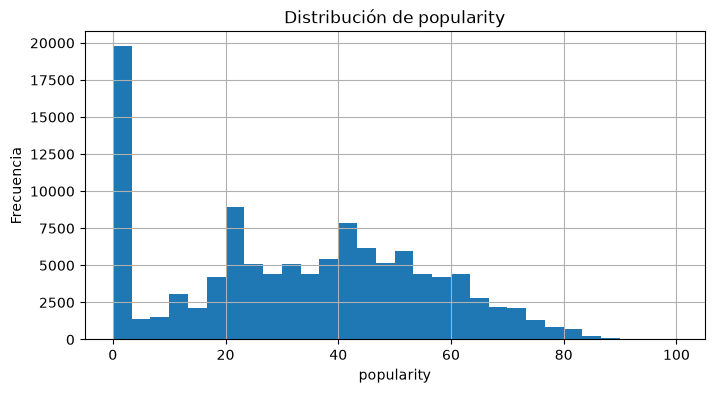

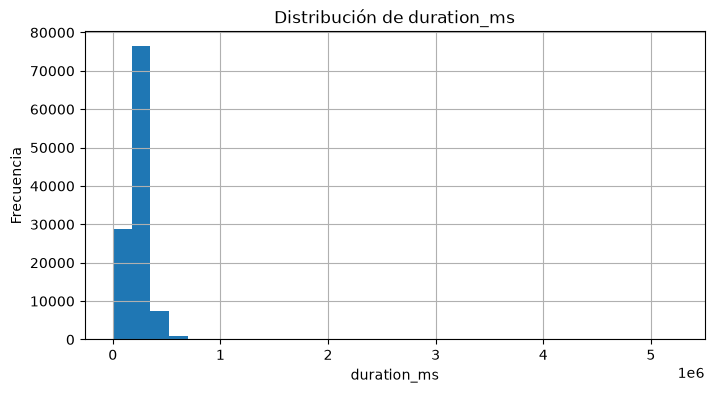

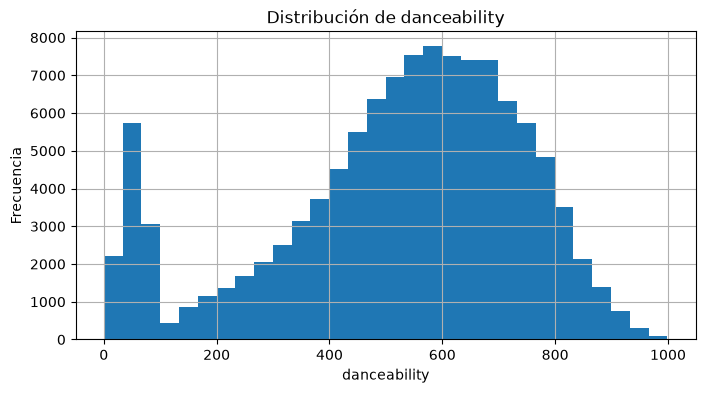

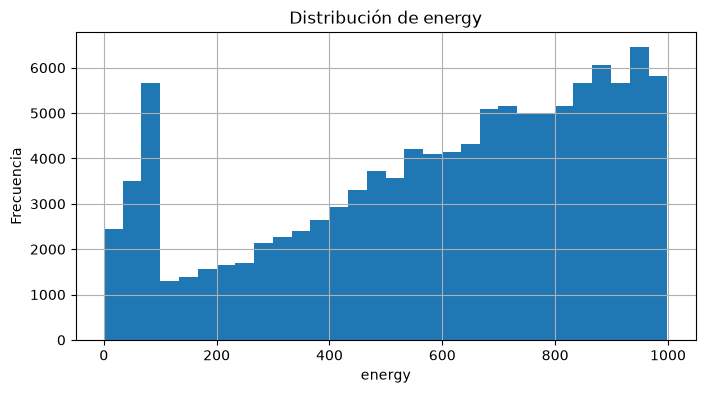

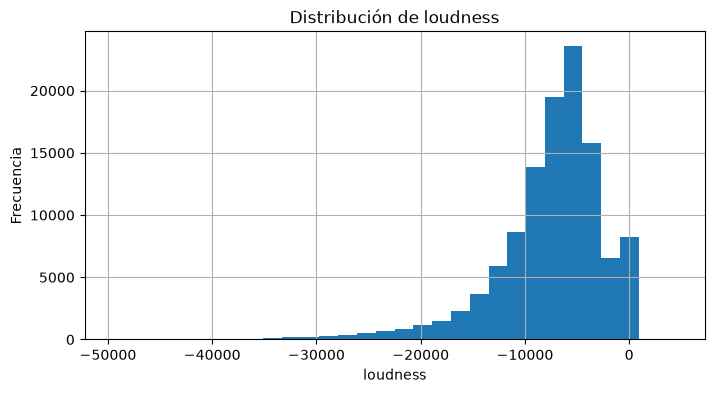

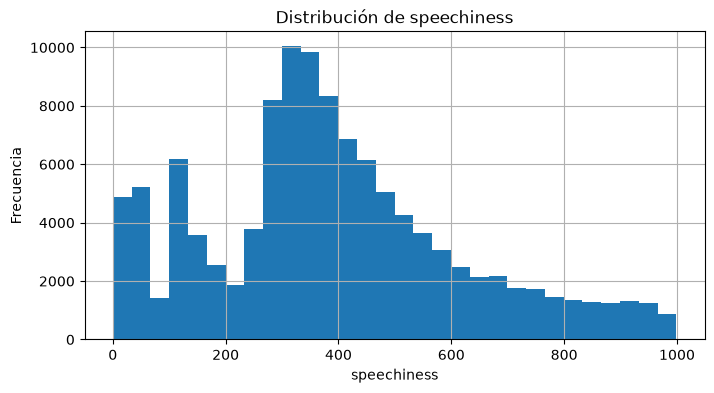

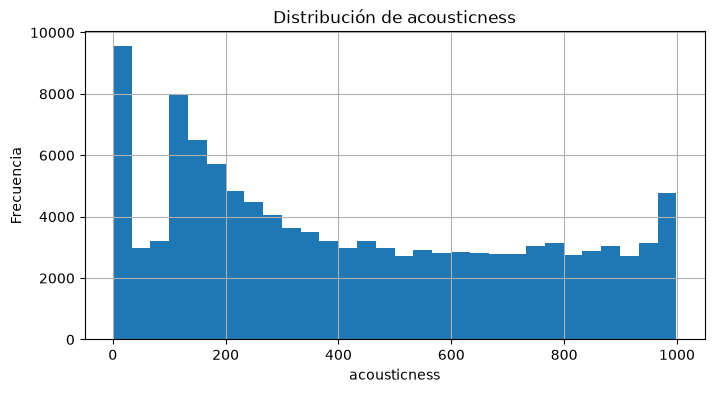

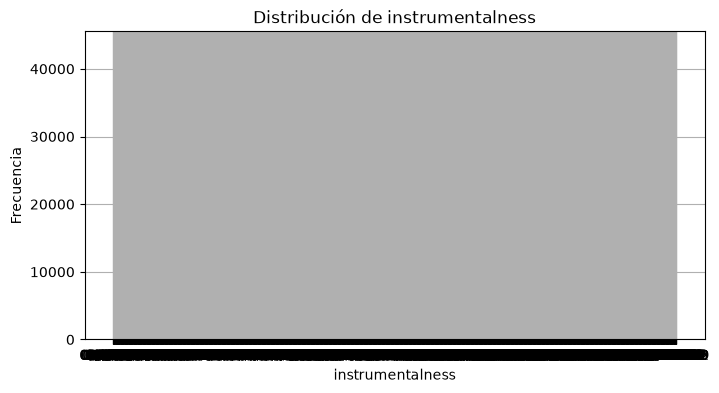

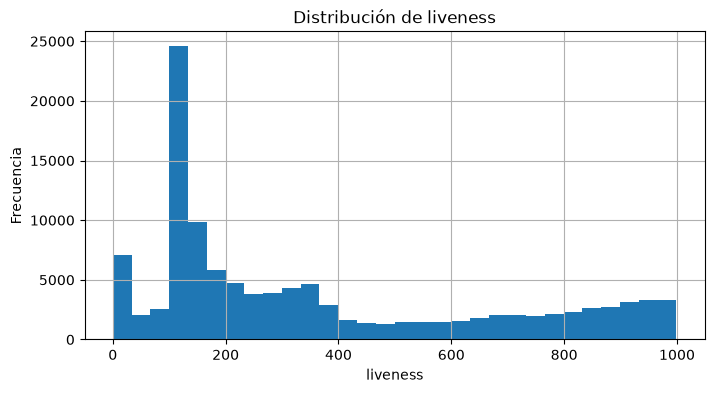

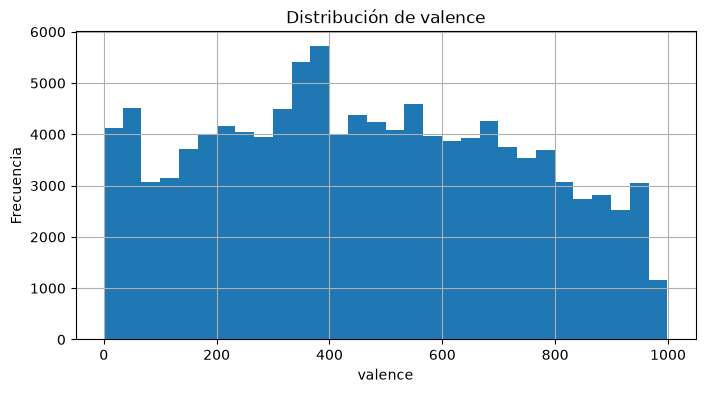

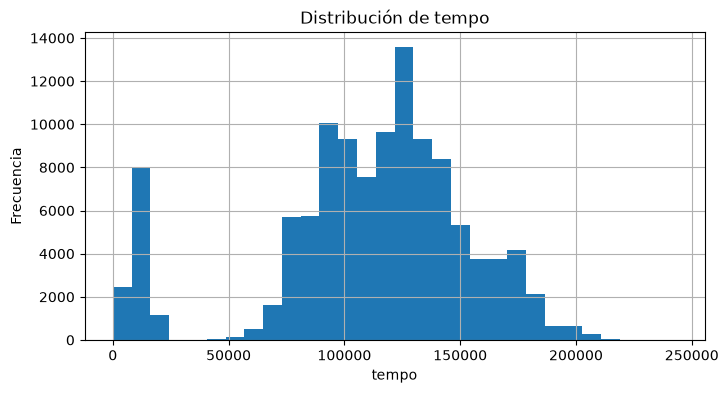

In [ ]:
import matplotlib.pyplot as plt

for col in numeric_columns:
    plt.figure(figsize=(8, 4))
    df[col].hist(bins=30)
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

### 6.3 Rangos

Se compararán los valores observados con los dominios esperados para cada variable, con el objetivo de identificar valores fuera de rango.

In [ ]:
expected_ranges = {
    "popularity": (0, 100),
    "duration_ms": (0, None),
    "danceability": (0, 1),
    "energy": (0, 1),
    "loudness": (None, 0),
    "speechiness": (0, 1),
    "acousticness": (0, 1),
    "instrumentalness": (0, 1),
    "liveness": (0, 1),
    "valence": (0, 1),
    "tempo": (0, None)
}

for col, (minimum, maximum) in expected_ranges.items():
    values = pd.to_numeric(df[col], errors="coerce")
    
    invalid = pd.Series(False, index=df.index)
    
    if minimum is not None:
        invalid |= values < minimum
    if maximum is not None:
        invalid |= values > maximum
    
    print(f"{col}: {invalid.sum()} valores fuera de rango")

popularity: 0 valores fuera de rango
duration_ms: 0 valores fuera de rango
danceability: 113839 valores fuera de rango
energy: 113910 valores fuera de rango
loudness: 90 valores fuera de rango
speechiness: 113713 valores fuera de rango
acousticness: 108977 valores fuera de rango
instrumentalness: 52982 valores fuera de rango
liveness: 113479 valores fuera de rango
valence: 113633 valores fuera de rango
tempo: 0 valores fuera de rango


### 6.4 Valores imposibles

Se verificará específicamente la presencia de valores que no puedan interpretarse como datos numéricos válidos, incluyendo valores no convertibles y valores negativos cuando el dominio no los permite.

In [ ]:
for col in numeric_columns:
    numeric_values = pd.to_numeric(df[col], errors="coerce")
    non_numeric = numeric_values.isna() & df[col].notna()
    
    print(f"{col}: {non_numeric.sum()} valores no numéricos")

popularity: 0 valores no numéricos
duration_ms: 0 valores no numéricos
danceability: 0 valores no numéricos
energy: 0 valores no numéricos
loudness: 0 valores no numéricos
speechiness: 0 valores no numéricos
acousticness: 0 valores no numéricos
instrumentalness: 22169 valores no numéricos
liveness: 0 valores no numéricos
valence: 0 valores no numéricos
tempo: 0 valores no numéricos


### 6.4.1 Investigación de `instrumentalness`

El perfilamiento detectó 22,169 valores que no pudieron convertirse mediante `pd.to_numeric`. Sin embargo, la inspección directa del dataset muestra valores decimales aparentemente válidos.

Se analizará el contenido original de la columna para identificar qué representación tienen esos valores y determinar si se trata de valores realmente no numéricos, valores numéricos almacenados como texto o una combinación de formatos.

In [ ]:
instrumental_numeric = pd.to_numeric(
    df["instrumentalness"],
    errors="coerce"
)

non_numeric_instrumentalness = df.loc[
    instrumental_numeric.isna() & df["instrumentalness"].notna(),
    "instrumentalness"
]

print(f"Cantidad: {len(non_numeric_instrumentalness)}")
print("\nValores más frecuentes:")
print(non_numeric_instrumentalness.value_counts().head(30))

Cantidad: 22169

Valores más frecuentes:
instrumentalness
0,00359     166
0,000012     95
0,000133     92
0,00114      79
0,000119     66
0,000181     64
0,000211     64
0,00223      63
0,00011      62
0,00333      61
0,000138     61
0,00117      60
0,00168      58
0,000011     57
0,000107     56
0,000199     56
0,00181      56
0,000206     55
0,000117     55
0,000118     53
0,000146     52
0,00128      52
0,000971     51
0,000104     50
0,000116     50
0,00103      49
0,000106     49
0,00107      48
0,00127      48
0,000175     47
Name: count, dtype: int64


Los valores identificados en `instrumentalness` corresponden a números decimales representados mediante coma como separador decimal. Por tanto, la conversión anterior los clasificó incorrectamente como valores no numéricos.

Se realizará una conversión específica reemplazando la coma decimal por punto, con el objetivo de evaluar correctamente su rango y comportamiento.

In [ ]:
instrumentalness_numeric = pd.to_numeric(
    df["instrumentalness"]
    .astype(str)
    .str.replace(",", ".", regex=False),
    errors="coerce"
)

print(f"Valores no convertibles: {instrumentalness_numeric.isna().sum()}")
print("\nEstadística descriptiva:")
display(instrumentalness_numeric.describe())

Valores no convertibles: 0

Estadística descriptiva:


count    114000.000000
mean        221.672703
std         321.981320
min           0.000000
25%           0.000000
50%           0.003790
75%         374.000000
max         999.000000
Name: instrumentalness, dtype: float64

### 6.4.2 Investigación de escalas

La revisión de `instrumentalness` evidencia que la columna contiene valores decimales en escala 0–1 y otros valores representados en una escala aproximada 0–1000.

Se verificará la representación de las principales características musicales para determinar si existe un patrón común de escalamiento o si `instrumentalness` presenta un problema específico.

In [ ]:
musical_columns = [
    "danceability",
    "energy",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence"
]

for col in musical_columns:
    values = pd.to_numeric(
        df[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )
    
    print(f"{col}:")
    print(f"  min = {values.min()}")
    print(f"  max = {values.max()}")
    print(f"  valores <= 1 = {(values <= 1).sum()}")
    print(f"  valores > 1 = {(values > 1).sum()}")

danceability:
  min = 0
  max = 999
  valores <= 1 = 161
  valores > 1 = 113839
energy:
  min = 0
  max = 999
  valores <= 1 = 90
  valores > 1 = 113910
speechiness:
  min = 0
  max = 999
  valores <= 1 = 287
  valores > 1 = 113713
acousticness:
  min = 0
  max = 999
  valores <= 1 = 5023
  valores > 1 = 108977
instrumentalness:
  min = 0.0
  max = 999.0
  valores <= 1 = 61018
  valores > 1 = 52982
liveness:
  min = 0
  max = 999
  valores <= 1 = 521
  valores > 1 = 113479
valence:
  min = 0
  max = 999
  valores <= 1 = 367
  valores > 1 = 113633


### 6.4.3 Identificación de representaciones

Se verificará la proporción de valores representados en escala 0–1 y escala 0–1000 para cada característica musical.

El objetivo es determinar si las variables presentan una representación homogénea o si existen mezclas de escala dentro de una misma columna. Esta información será necesaria antes de evaluar correctamente rangos y valores extremos.

In [ ]:
for col in musical_columns:
    values = pd.to_numeric(
        df[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )
    
    scale_01 = (values <= 1).sum()
    scale_1000 = (values > 1).sum()
    
    print(
        f"{col}: "
        f"0–1 = {scale_01:,} | "
        f">1 = {scale_1000:,}"
    )

danceability: 0–1 = 161 | >1 = 113,839
energy: 0–1 = 90 | >1 = 113,910
speechiness: 0–1 = 287 | >1 = 113,713
acousticness: 0–1 = 5,023 | >1 = 108,977
instrumentalness: 0–1 = 61,018 | >1 = 52,982
liveness: 0–1 = 521 | >1 = 113,479
valence: 0–1 = 367 | >1 = 113,633


In [ ]:
musical_columns = [
    "danceability",
    "energy",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence"
]

scale_check = []

for col in musical_columns:
    values = pd.to_numeric(
        df[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

    scaled = values[values > 1] / 1000

    scale_check.append({
        "column": col,
        "count_gt_1": len(scaled),
        "min_after_div_1000": scaled.min(),
        "max_after_div_1000": scaled.max(),
        "count_in_0_1_after_div": ((scaled >= 0) & (scaled <= 1)).sum(),
        "count_outside_0_1_after_div": ((scaled < 0) | (scaled > 1)).sum()
    })

scale_check_df = pd.DataFrame(scale_check)

scale_check_df

,column,count_gt_1,min_after_div_1000,max_after_div_1000,count_in_0_1_after_div,count_outside_0_1_after_div
0,danceability,113839,0.002,0.999,113839,0
1,energy,113910,0.002,0.999,113910,0
2,speechiness,113713,0.002,0.999,113713,0
3,acousticness,108977,0.002,0.999,108977,0
4,instrumentalness,52982,0.002,0.999,52982,0
5,liveness,113479,0.002,0.999,113479,0
6,valence,113633,0.002,0.999,113633,0


In [ ]:
scale_check_other = []

for col in ["loudness", "tempo"]:
    values = pd.to_numeric(
        df[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

    scaled = values / 1000

    scale_check_other.append({
        "column": col,
        "min_original": values.min(),
        "max_original": values.max(),
        "min_after_div_1000": scaled.min(),
        "max_after_div_1000": scaled.max()
    })

scale_check_other_df = pd.DataFrame(scale_check_other)

scale_check_other_df

,column,min_original,max_original,min_after_div_1000,max_after_div_1000
0,loudness,-49531,4532,-49.531,4.532
1,tempo,0,243372,0.000,243.372


### 6.5 Valores extremos

Se identificarán valores estadísticamente extremos mediante el rango intercuartílico (IQR). Estos valores serán considerados candidatos a revisión, no errores automáticamente.

In [ ]:
numeric_analysis = pd.DataFrame()

# Variables con escala ×1000
scaled_columns = [
    "danceability",
    "energy",
    "speechiness",
    "acousticness",
    "liveness",
    "valence",
    "loudness",
    "tempo"
]

for col in scaled_columns:
    numeric_analysis[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    ) / 1000

# Instrumentalness: escala mixta
instrumentalness = pd.to_numeric(
    df["instrumentalness"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)

numeric_analysis["instrumentalness"] = instrumentalness.where(
    instrumentalness <= 1,
    instrumentalness / 1000
)

# Variables que no requieren conversión
numeric_analysis["popularity"] = pd.to_numeric(
    df["popularity"],
    errors="coerce"
)

numeric_analysis["duration_ms"] = pd.to_numeric(
    df["duration_ms"],
    errors="coerce"
)


# Detección de valores extremos mediante IQR
outlier_results = []

for col in numeric_analysis.columns:
    series = numeric_analysis[col].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outliers = series[
        (series < lower_limit) |
        (series > upper_limit)
    ]

    outlier_results.append({
        "column": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_limit": lower_limit,
        "upper_limit": upper_limit,
        "outlier_count": len(outliers),
        "outlier_percentage": len(outliers) / len(series) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df

,column,Q1,Q3,IQR,lower_limit,upper_limit,outlier_count,outlier_percentage
0,danceability,0.40400,0.6850,0.28100,-0.017500,1.106500,0,0.000000
1,energy,0.39800,0.8390,0.44100,-0.263500,1.500500,0,0.000000
2,speechiness,0.26100,0.5120,0.25100,-0.115500,0.888500,3814,3.345614
3,acousticness,0.15700,0.6970,0.54000,-0.653000,1.507000,0,0.000000
4,liveness,0.11800,0.6130,0.49500,-0.624500,1.355500,0,0.000000
5,valence,0.24700,0.6830,0.43600,-0.407000,1.337000,0,0.000000
6,loudness,-9.56725,-4.3080,5.25925,-17.456125,3.580875,5655,4.960526
7,tempo,92.00300,138.0895,46.08650,22.873250,207.219250,11753,10.309649
8,instrumentalness,0.00000,0.3760,0.37600,-0.564000,0.940000,2698,2.366667
9,popularity,17.00000,50.0000,33.00000,-32.500000,99.500000,2,0.001754


In [ ]:
instrumental_raw = pd.to_numeric(
    df["instrumentalness"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)


instrumental_normalized = instrumental_raw.where(
    instrumental_raw <= 1,
    instrumental_raw / 1000
)


instrumental_outliers = instrumental_normalized[
    (instrumental_normalized < -0.564) |
    (instrumental_normalized > 0.940)
]


instrumental_check = {
    "total_outliers": len(instrumental_outliers),
    "outliers_below_0": (instrumental_outliers < 0).sum(),
    "outliers_above_0_940": (instrumental_outliers > 0.940).sum(),
    "max_normalized": instrumental_outliers.max(),
    "min_normalized": instrumental_outliers.min()
}

instrumental_check

{'total_outliers': 2698,
 'outliers_below_0': np.int64(0),
 'outliers_above_0_940': np.int64(2698),
 'max_normalized': np.float64(1.0),
 'min_normalized': np.float64(0.941)}

In [ ]:
instrumental_outlier_examples = pd.DataFrame({
    "original": instrumental_raw.loc[instrumental_outliers.index],
    "normalized": instrumental_normalized.loc[instrumental_outliers.index]
}).sort_values("normalized", ascending=False)

instrumental_outlier_examples.head(20)

,original,normalized
25076,1.0,1.0
2526,1.0,1.0
22828,1.0,1.0
22159,1.0,1.0
22121,1.0,1.0
17839,1.0,1.0
21568,1.0,1.0
29385,1.0,1.0
28889,1.0,1.0
28429,1.0,1.0


instrumentalness presenta 2,698 valores identificados como extremos mediante el criterio IQR (2.37%). Sin embargo, todos se encuentran dentro del dominio válido 0–1, específicamente entre 0.941 y 1.000. Por tanto, corresponden a valores estadísticamente extremos, pero no a valores inválidos.

## Hallazgos

El análisis mediante IQR identificó valores extremos en speechiness, loudness, tempo, instrumentalness, duration_ms y popularity. Los valores detectados no implican por sí mismos errores de calidad: en el caso de instrumentalness, por ejemplo, todos los extremos permanecen dentro de su dominio válido. Por ello, los outliers se conservan como observaciones potencialmente válidas y no se plantea su eliminación durante el perfilamiento.

### 6.6 Hallazgos

El análisis del contenido numérico permitió identificar los siguientes hallazgos:

- `popularity` presenta valores dentro del rango esperado de 0–100. Se identificaron únicamente 2 valores estadísticamente extremos mediante IQR, por lo que no representan un problema significativo de calidad.

- `duration_ms` presenta valores en milisegundos y una distribución con 5,617 valores extremos según IQR (4.93%). Estos valores se consideran potencialmente válidos y no se clasifican como errores únicamente por su comportamiento estadístico.

- Las variables `danceability`, `energy`, `speechiness`, `acousticness`, `liveness` y `valence` presentan una representación escalada ×1000 en la fuente. Los valores superiores a 1, al dividirse entre 1000, quedan dentro del dominio semántico 0–1.

- `instrumentalness` presenta una inconsistencia de representación: 61,018 valores ya se encuentran en escala 0–1, mientras que 52,982 están representados en escala ×1000. Esta columna requiere una normalización condicional durante el ETL.

- `loudness` también presenta una representación escalada ×1000. Después de interpretar correctamente la escala, sus valores se encuentran entre -49.531 y 4.532 dB.

- `tempo` presenta una representación escalada ×1000, con valores entre 0 y 243.372 BPM. El valor 0 requiere una revisión posterior, ya que no representa un tempo musical convencional y podría corresponder a un valor ausente o no informado.

- El análisis IQR identificó valores extremos en `speechiness` (3,814), `loudness` (5,655), `tempo` (11,753), `instrumentalness` (2,698), `duration_ms` (5,617) y `popularity` (2). Estos valores son estadísticamente atípicos, pero no se consideran automáticamente inválidos.

- En particular, los 2,698 valores extremos de `instrumentalness` se encuentran entre 0.941 y 1.000, por lo que permanecen dentro de su dominio válido.

- No se identificaron valores negativos en las variables cuyo dominio semántico corresponde a 0–1.

- El principal problema de calidad identificado en el contenido numérico corresponde a la inconsistencia de representación y escala, especialmente en `instrumentalness`, más que a la presencia de valores fuera de dominio.

En consecuencia, durante el ETL será necesario normalizar las escalas numéricas antes de utilizarlas en el modelo dimensional, preservando los valores estadísticamente extremos que continúen siendo semánticamente válidos.

# 8 Resumen de observaciones

## Resumen del Análisis de Calidad y Estructura del Dataset

Este notebook resume los hallazgos clave y los impactos identificados durante la evaluación del conjunto de datos.

---

### 1. Estructura y Completitud

En cuanto a la **estructura y completitud** del conjunto de datos, se analizó un *dataset* compuesto por 114,000 registros y 21 columnas, el cual proporciona el contexto general de la información. Durante la revisión de completitud, se identificaron valores nulos en los campos de `artists`, `album_name` y `track_name`, lo que hace indispensable aplicar un tratamiento de datos durante el proceso de extracción, transformación y carga (ETL).

---

### 2. Duplicación, Granularidad e Identificación

Respecto a la **duplicación, granularidad e identificación**, no existen filas completamente duplicadas en la base de datos; sin embargo, se detectaron 444 combinaciones repetidas entre `track_id` y `track_genre`, lo que requerirá un proceso de deduplicación. La granularidad conceptual corresponde a la observación de una pista musical asociada a un género en particular. En este contexto, el campo `track_id` identifica la pista, mientras que `track_genre` contribuye a la identificación de cada observación, aspecto fundamental para el correcto diseño del modelo dimensional.

---

### 3. Atributos Categóricos

En relación con los **atributos categóricos**, se detectaron variaciones en el uso de mayúsculas y minúsculas en los nombres de álbumes (`album_name`) y canciones (`track_name`), por lo que será necesaria una etapa de normalización. Asimismo, las variables `artists`, `album_name` y `track_name` presentan una alta cardinalidad, funcionando primordialmente como atributos descriptivos del conjunto de datos.

---

### 4. Variables Numéricas

Sobre el análisis de las **variables numéricas**, se observó que diversas métricas musicales están expresadas en una escala multiplicada por 1,000, requiriendo su debida normalización. Un caso particular es la variable `instrumentalness`, la cual muestra una representación mixta entre la escala estándar de 0 a 1 y la escala ×1000, exigiendo un tratamiento condicional específico. Adicionalmente, se identificaron valores estadísticamente extremos en múltiples campos numéricos que demandan validación antes de tomar decisiones, evitando su eliminación automática.

---

### 5. Dimensión Temporal

Finalmente, en la dimensión **temporal**, el conjunto de datos carece de variables de fecha o tiempo utilizables, por lo que no es factible realizar análisis de series de tiempo ni evaluaciones de carácter temporal.

### 8.2 Evidencia relevante

Los principales hallazgos identificados durante el perfilamiento cuentan con la siguiente evidencia cuantitativa:

| Área | Evidencia |
|---|---|
| Estructura | 114,000 registros y 21 columnas |
| Completitud | Se identificaron valores nulos en `artists`, `album_name` y `track_name` |
| Duplicación | 0 filas completamente duplicadas |
| Identificación | `track_id` presenta 89,741 valores únicos (78.72%) |
| Grano | 444 combinaciones `track_id + track_genre` están repetidas, involucrando 894 registros |
| Multigénero | 16,299 `track_id` aparecen asociados a más de un género |
| Variación multigénero | 15,579 `track_id` no presentan variación en atributos distintos de `track_genre`; 720 presentan variación únicamente en `popularity` |
| Categóricos | `track_genre` contiene 114 categorías |
| Formato categórico | Se identificaron 414 grupos con variaciones de capitalización en `album_name` y 1,163 en `track_name` |
| Escalas numéricas | Varias variables musicales presentan representación ×1000 respecto a su escala semántica |
| `instrumentalness` | Presenta representación mixta: valores en escala 0–1 y valores en escala ×1000 |
| Valores extremos | Se identificaron valores estadísticamente extremos en `duration_ms`, `speechiness`, `loudness`, `tempo`, `instrumentalness` y `popularity` |
| Temporalidad | No existe una variable temporal utilizable en la fuente |

Esta evidencia permite distinguir entre problemas de calidad, características propias de los datos y decisiones que deben resolverse durante el diseño del ETL.

### 8.3 Posibles riesgos

A partir de los hallazgos obtenidos se identifican los siguientes riesgos potenciales:

| Riesgo | Causa | Posible impacto |
|---|---|---|
| Ambigüedad del identificador de registro | `track_id` no identifica de forma única cada observación | Errores de deduplicación o modelado |
| Registros repetidos | Existen 444 combinaciones repetidas de `track_id + track_genre` | Sobreconteo de registros y métricas |
| Valores nulos descriptivos | `artists`, `album_name` y `track_name` contienen valores ausentes | Registros incompletos en dimensiones descriptivas |
| Inconsistencia de formato | Variaciones de capitalización en nombres | Fragmentación de valores equivalentes |
| Escalas numéricas inconsistentes | Variables representadas en escala 0–1 y ×1000 | Cálculos y análisis incorrectos |
| Representación mixta de `instrumentalness` | Una misma columna utiliza dos escalas | Riesgo de valores incorrectamente interpretados |
| Valores extremos | Algunas variables presentan observaciones estadísticamente atípicas | Posible distorsión de análisis si se eliminan o tratan incorrectamente |
| `tempo = 0` | Valor fuera de lo habitual para un tempo musical | Posible valor no informado o inconsistente |
| Variación de `popularity` | Algunos `track_id` presentan distintos valores de popularidad entre observaciones | Ambigüedad sobre qué valor conservar o cómo modelarlo |
| Ausencia de temporalidad | No existe una fecha o periodo utilizable | Limita análisis históricos y dimensiones temporales |

Estos riesgos no implican necesariamente que los registros deban eliminarse. Su tratamiento debe definirse de acuerdo con la granularidad, las reglas de negocio y los objetivos del modelo dimensional.

### 8.4 Elementos pendientes de requerimientos

El perfilamiento permitió identificar varios aspectos que requieren definición antes de implementar las transformaciones definitivas del ETL:

1. **Definición del grano**
   - Confirmar que la unidad de análisis corresponde a una observación de una pista asociada a un género.
   - Validar el uso de `track_id + track_genre` como combinación de referencia del registro.

2. **Tratamiento de duplicados**
   - Definir qué registro conservar cuando se repite una combinación `track_id + track_genre`.
   - Debido a que los 444 grupos repetidos presentan los mismos atributos de negocio, se puede considerar una estrategia de deduplicación basada en conservar una única observación.

3. **Tratamiento de valores nulos**
   - Definir qué hacer con valores ausentes de `artists`, `album_name` y `track_name`.
   - Determinar si deben conservarse como desconocidos, reemplazarse por una categoría estándar o excluirse bajo alguna regla de negocio.

4. **Normalización de valores categóricos**
   - Definir una representación estándar para `explicit`.
   - Determinar si las diferencias de capitalización en `album_name` y `track_name` deben normalizarse.

5. **Normalización numérica**
   - Confirmar las escalas esperadas para las variables musicales.
   - Normalizar las variables representadas ×1000.
   - Aplicar un tratamiento condicional a `instrumentalness` debido a su representación mixta.

6. **Tratamiento de valores extremos**
   - Determinar si los valores estadísticamente extremos deben conservarse, transformarse o excluirse.
   - Evitar eliminarlos únicamente por ser atípicos cuando permanecen dentro de su dominio semántico.

7. **Tratamiento de `tempo = 0`**
   - Confirmar si representa un valor válido, desconocido o ausente.

8. **Tratamiento de `popularity`**
   - Definir cómo debe gestionarse cuando una misma pista presenta diferentes valores de popularidad según la observación.

9. **Dimensión temporal**
   - Confirmar que el modelo no requiere análisis temporal, dado que la fuente no proporciona una variable temporal utilizable.

Estas definiciones deberán ser validadas contra los requerimientos del negocio antes de establecer las reglas definitivas de transformación y carga.